In [1]:
import os
import shutil
import random
import uuid
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.applications.xception import Xception, preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout, BatchNormalization, GlobalAveragePooling2D, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
from IPython.display import FileLink, display

# --- CONFIGURATION ---
ORIGINAL_DIR = Path('/kaggle/input/datasets/smrnahin/hybrid/Original')
FAKE_DIR = Path('/kaggle/input/datasets/smrnahin/hybrid/Original')
OUTPUT_DIR = Path('./hybrid_dataset')

CLASSES = ['Healthy', 'Myopia', 'Macular Scar', 'Diabetic Retinopathy']
TARGET_TOTAL = 1509
IMG_SHAPE = 299  # Xception natively uses 299x299
BATCH_SIZE = 32
EPOCHS = 50
SEED = 42

2026-05-06 11:31:31.658254: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1778067091.868514      56 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1778067091.926639      56 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1778067092.402273      56 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778067092.402317      56 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778067092.402320      56 computation_placer.cc:177] computation placer alr

In [2]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Building hybrid dataset (Target: {TARGET_TOTAL} images/class)...\n")

for cls in CLASSES:
    orig_cls_dir = ORIGINAL_DIR / cls
    out_cls_dir = OUTPUT_DIR / cls
    out_cls_dir.mkdir(parents=True, exist_ok=True)

    # Handle the spelling typo in the Kaggle fake dataset
    if cls == 'Macular Scar' and not (FAKE_DIR / 'Macular_Scar').exists():
        fake_folder_name = 'Macular_Sacr'
    else:
        fake_folder_name = cls.replace(" ", "_")
    
    fake_cls_dir = FAKE_DIR / fake_folder_name

    # --- STEP A: Copy Originals ---
    orig_count = 0
    if orig_cls_dir.exists():
        orig_images = list(orig_cls_dir.glob('*.*'))
        for img_path in orig_images:
            dst = out_cls_dir / f"mix_{uuid.uuid4().hex[:6]}_orig_{img_path.name}"
            shutil.copy(img_path, dst)
            orig_count += 1

    # --- STEP B: Calculate Deficit & Copy Fakes ---
    needed_fakes = TARGET_TOTAL - orig_count
    fake_count = 0
    if needed_fakes > 0 and fake_cls_dir.exists():
        fake_images = list(fake_cls_dir.glob('*.*'))
        random.shuffle(fake_images)
        for img_path in fake_images[:needed_fakes]:
            dst = out_cls_dir / f"mix_{uuid.uuid4().hex[:6]}_fake_{img_path.name}"
            shutil.copy(img_path, dst)
            fake_count += 1

    print(f"[{cls}] Originals: {orig_count} | Fakes: {fake_count} | Total: {orig_count + fake_count}")

print("-" * 50)
print("Hybrid dataset successfully compiled for Xception!")

Building hybrid dataset (Target: 1509 images/class)...

[Healthy] Originals: 1024 | Fakes: 485 | Total: 1509
[Myopia] Originals: 500 | Fakes: 500 | Total: 1000
[Macular Scar] Originals: 444 | Fakes: 0 | Total: 444
[Diabetic Retinopathy] Originals: 1509 | Fakes: 0 | Total: 1509
--------------------------------------------------
Hybrid dataset successfully compiled for Xception!


In [3]:
# Setup Data Generators
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2,
    rotation_range=15,
    zoom_range=0.15,
    width_shift_range=0.15,
    height_shift_range=0.15,
    horizontal_flip=False,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

# Flow from Directory
train_data = train_datagen.flow_from_directory(
    OUTPUT_DIR,
    subset='training',
    class_mode="categorical",
    target_size=(IMG_SHAPE, IMG_SHAPE),
    color_mode='rgb',
    shuffle=True,
    batch_size=BATCH_SIZE,
    seed=SEED
)

val_data = val_datagen.flow_from_directory(
    OUTPUT_DIR,
    subset='validation',
    class_mode="categorical",
    target_size=(IMG_SHAPE, IMG_SHAPE),
    color_mode="rgb",
    shuffle=False,
    batch_size=BATCH_SIZE,
    seed=SEED
)

Found 3572 images belonging to 4 classes.
Found 890 images belonging to 4 classes.


In [4]:
# --- 1. LOAD THE BASE MODEL ---
base_model = Xception(
    input_shape=(IMG_SHAPE, IMG_SHAPE, 3),
    include_top=False,
    weights='imagenet'
)

# --- 2. FINE-TUNING SETUP ---
base_model.trainable = True

# Freeze all layers except the top 16 (unfreezes the final Xception block14)
for layer in base_model.layers[:-16]:
    layer.trainable = False

# --- 3. BUILD THE CLASSIFICATION HEAD ---
xception_model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dropout(0.3),
    BatchNormalization(),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(len(CLASSES), activation='softmax')
])

# --- 4. MODEL COMPILATION ---
custom_optimizer = Adam(learning_rate=1e-4)

xception_model.compile(
    optimizer=custom_optimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

xception_model.summary()

I0000 00:00:1778067169.074003      56 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xception (Functional)           │ (None, 10, 10, 2048)   │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       131,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,001,324 (80.11 MB)

 Trainable params: 6,924,004 (26.41 MB)

 Non-trainable params: 14,077,320 (53.70 MB)

In [5]:
# --- CALLBACKS SETUP ---
checkpoint = ModelCheckpoint(
    filepath="Best_Xception_Model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor='val_accuracy',
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    verbose=1
)

callbacks_list = [checkpoint, early_stopping, reduce_lr]

# --- MODEL TRAINING ---
print("Starting Xception Fine-Tuning...")

xception_history = xception_model.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS,
    callbacks=callbacks_list
)

Starting Xception Fine-Tuning...


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50


I0000 00:00:1778067183.656482     146 service.cc:152] XLA service 0x7bd098002180 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1778067183.656550     146 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1778067185.585987     146 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-05-06 11:33:18.331025: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-06 11:33:18.527698: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-06 11:33:19.994612: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accur

 72/112 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - accuracy: 0.5282 - loss: 1.3387

2026-05-06 11:35:09.546924: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-06 11:35:09.785996: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-06 11:35:10.961791: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-06 11:35:11.224575: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-06 11:35:16.055362: E external/local_xla/xla/stream_

112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5706 - loss: 1.2325

2026-05-06 11:36:53.119954: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-06 11:36:53.360978: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-06 11:36:54.586629: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-06 11:36:54.852081: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_accuracy improved from -inf to 0.72135, saving model to Best_Xception_Model.keras
112/112 ━━━━━━━━━━━━━━━━━━━━ 256s 2s/step - accuracy: 0.5714 - loss: 1.2304 - val_accuracy: 0.7213 - val_loss: 0.8188 - learning_rate: 1.0000e-04
Epoch 2/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7535 - loss: 0.7025
Epoch 2: val_accuracy improved from 0.72135 to 0.77640, saving model to Best_Xception_Model.keras
112/112 ━━━━━━━━━━━━━━━━━━━━ 152s 1s/step - accuracy: 0.7538 - loss: 0.7019 - val_accuracy: 0.7764 - val_loss: 0.6222 - learning_rate: 1.0000e-04
Epoch 3/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8150 - loss: 0.5534
Epoch 3: val_accuracy did not improve from 0.77640
112/112 ━━━━━━━━━━━━━━━━━━━━ 151s 1s/step - accuracy: 0.8150 - loss: 0.5533 - val_accuracy: 0.7764 - val_loss: 0.5811 - learning_rate: 1.0000e-04
Epoch 4/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8327 - loss: 0.4940
Epoch 4: val_accuracy improved from 0.77640 to 0.87303, saving

Generating predictions...
28/28 ━━━━━━━━━━━━━━━━━━━━ 43s 1s/step 


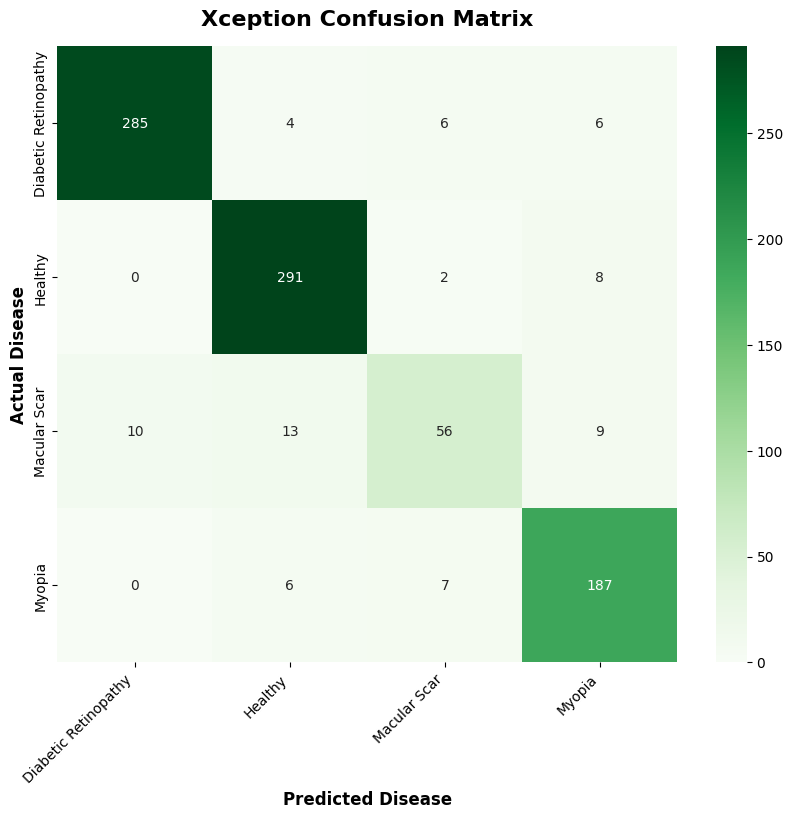

Classification Report:

                       precision    recall  f1-score   support

Diabetic Retinopathy       0.97      0.95      0.96       301
             Healthy       0.93      0.97      0.95       301
        Macular Scar       0.79      0.64      0.70        88
              Myopia       0.89      0.94      0.91       200

            accuracy                           0.92       890
           macro avg       0.89      0.87      0.88       890
        weighted avg       0.92      0.92      0.92       890



In [6]:
# --- 1. GET PREDICTIONS ---
print("Generating predictions...")
val_data.reset() # Critical: Align labels properly
Y_pred = xception_model.predict(val_data)
y_pred_classes = np.argmax(Y_pred, axis=1)

true_labels = val_data.classes
class_names = list(val_data.class_indices.keys())

# --- 2. CONFUSION MATRIX ---
cm = confusion_matrix(true_labels, y_pred_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='g', cmap='Greens', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Disease', fontsize=12, fontweight='bold')
plt.ylabel('Actual Disease', fontsize=12, fontweight='bold')
plt.title('Xception Confusion Matrix', fontsize=16, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.savefig('Xception_Confusion_Matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# --- 3. CLASSIFICATION REPORT ---
report_text = classification_report(true_labels, y_pred_classes, target_names=class_names)
print("Classification Report:\n\n", report_text)

# Save as CSV
report_dict = classification_report(true_labels, y_pred_classes, target_names=class_names, output_dict=True)
pd.DataFrame(report_dict).T.to_csv('Xception_Classification_Report.csv', index=True)

# Save as TXT
with open('Xception_Classification_Report.txt', 'w') as f:
    f.write("Xception Classification Report\n")
    f.write("="*50 + "\n\n")
    f.write(report_text)

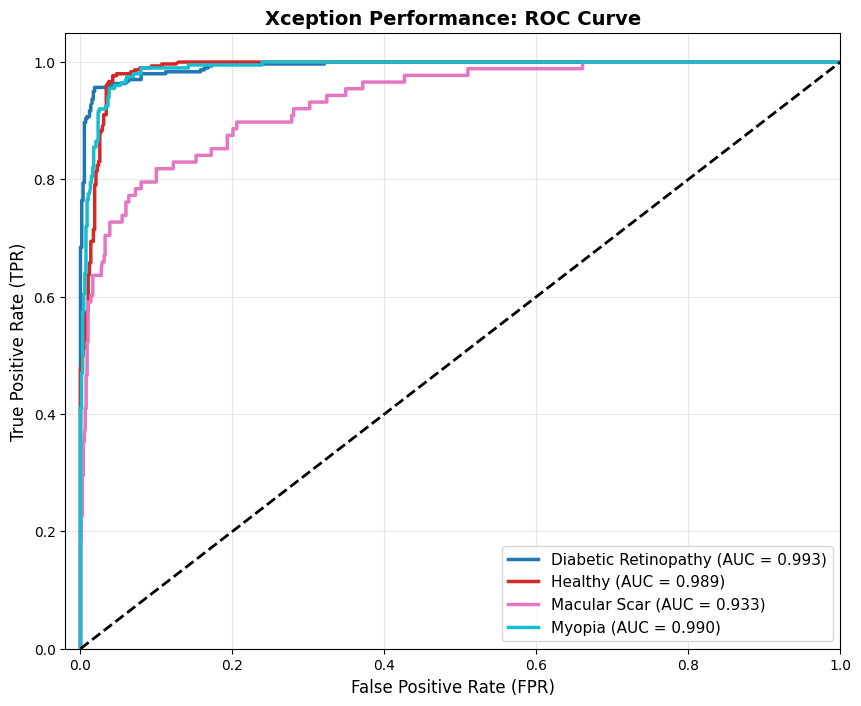


--- DOWNLOAD YOUR XCEPTION ARTIFACTS HERE ---


/kaggle/working/Best_Xception_Model.keras

/kaggle/working/Xception_Confusion_Matrix.png

/kaggle/working/Xception_Classification_Report.csv

/kaggle/working/Xception_Classification_Report.txt

/kaggle/working/Xception_ROC_Curve.png

/kaggle/working/Xception_AUC_Scores.csv

In [7]:
# --- 1. ROC CURVE CALCULATION ---
true_labels_bin = label_binarize(true_labels, classes=range(len(CLASSES)))

fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(len(CLASSES)):
    fpr[i], tpr[i], _ = roc_curve(true_labels_bin[:, i], Y_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# --- 2. PLOT ROC CURVE ---
plt.figure(figsize=(10, 8))
colors = plt.get_cmap('tab10')(np.linspace(0, 1, len(CLASSES)))

for i, color in zip(range(len(CLASSES)), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2.5,
             label=f'{class_names[i]} (AUC = {roc_auc[i]:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)
plt.title('Xception Performance: ROC Curve', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)

roc_image_path = 'Xception_ROC_Curve.png'
plt.savefig(roc_image_path, dpi=300, bbox_inches='tight')
plt.show()

# --- 3. SAVE AUC TO CSV ---
auc_df = pd.DataFrame({"Class": class_names, "AUC_Score": [roc_auc[i] for i in range(len(CLASSES))]})
auc_df.to_csv('Xception_AUC_Scores.csv', index=False)

# --- 4. GENERATE DOWNLOAD LINKS ---
print("\n--- DOWNLOAD YOUR XCEPTION ARTIFACTS HERE ---")
display(FileLink("Best_Xception_Model.keras", result_html_prefix="Trained Model: "))
display(FileLink("Xception_Confusion_Matrix.png", result_html_prefix="Confusion Matrix: "))
display(FileLink("Xception_Classification_Report.csv", result_html_prefix="Classification Report (CSV): "))
display(FileLink("Xception_Classification_Report.txt", result_html_prefix="Classification Report (TXT): "))
display(FileLink("Xception_ROC_Curve.png", result_html_prefix="ROC Curve Image: "))
display(FileLink("Xception_AUC_Scores.csv", result_html_prefix="AUC Scores CSV: "))

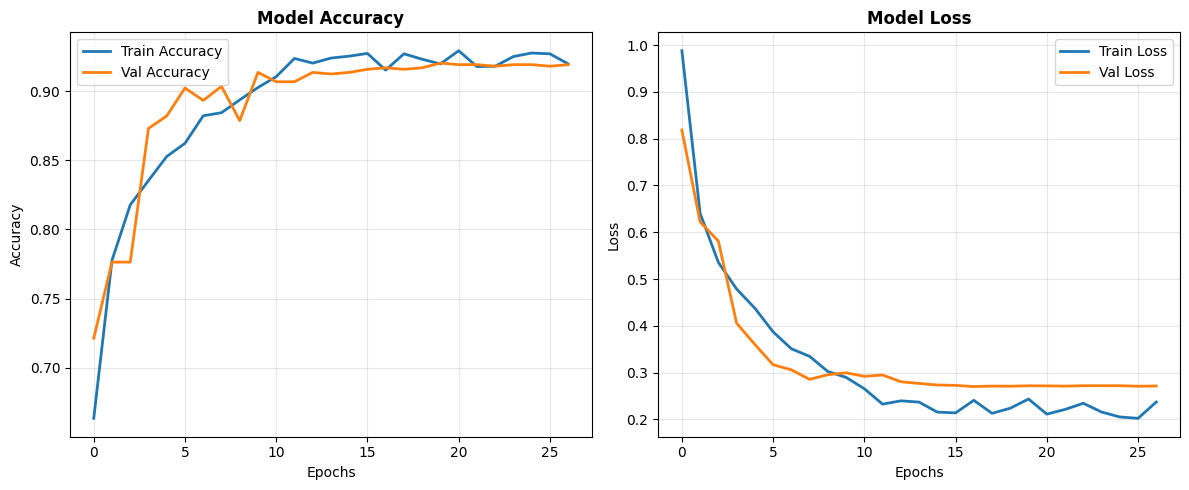

Packaging files into ZIP archive...

 [+] Added: Best_Xception_Model.keras
 [+] Added: Xception_Confusion_Matrix.png
 [+] Added: Xception_Classification_Report.csv
 [+] Added: Xception_Classification_Report.txt
 [+] Added: Xception_ROC_Curve.png
 [+] Added: Xception_AUC_Scores.csv
 [+] Added: Xception_Training_Curves.png

Successfully created Xception_Full_Evaluation_Suite.zip!


/kaggle/working/Xception_Full_Evaluation_Suite.zip

In [8]:
import zipfile
import os
from IPython.display import FileLink, display

# --- 1. PLOT & SAVE TRAINING CURVES ---
# Assuming 'xception_history' is your trained model's history object from Cell 5
plt.figure(figsize=(12, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(xception_history.history['accuracy'], label='Train Accuracy', lw=2)
plt.plot(xception_history.history['val_accuracy'], label='Val Accuracy', lw=2)
plt.title('Model Accuracy', fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(alpha=0.3)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(xception_history.history['loss'], label='Train Loss', lw=2)
plt.plot(xception_history.history['val_loss'], label='Val Loss', lw=2)
plt.title('Model Loss', fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(alpha=0.3)

curves_path = 'Xception_Training_Curves.png'
plt.tight_layout()
plt.savefig(curves_path, dpi=300, bbox_inches='tight')
plt.show()

# --- 2. ZIP ALL ARTIFACTS ---
zip_filename = 'Xception_Full_Evaluation_Suite.zip'

# List of all files generated throughout the notebook
files_to_zip = [
    'Best_Xception_Model.keras',
    'Xception_Confusion_Matrix.png',
    'Xception_Classification_Report.csv',
    'Xception_Classification_Report.txt',
    'Xception_ROC_Curve.png',
    'Xception_AUC_Scores.csv',
    'Xception_Training_Curves.png'
]

print("Packaging files into ZIP archive...\n")

with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for file in files_to_zip:
        if os.path.exists(file):
            zipf.write(file)
            print(f" [+] Added: {file}")
        else:
            print(f" [-] Warning: {file} not found. Skipping.")

# --- 3. GENERATE DOWNLOAD LINK ---
print(f"\nSuccessfully created {zip_filename}!")
display(FileLink(zip_filename, result_html_prefix="📦 Download Complete Suite (ZIP): "))